# 3.5 Image preprocessing and feature extraction

This notebook reports the completed image preprocessing and frozen-ResNet18 feature extraction stage. It reads the prepared manifest and cached feature maps; it does not rerun the CNN. Figures are exported as 300-dpi PNG and vector SVG files.

**Scope.** These figures describe this collected sample and the implemented preprocessing pipeline. They do not establish representativeness of all Vietnamese e-commerce imagery or downstream attribute accuracy.

In [1]:
from pathlib import Path
import json, hashlib, collections, math, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if not (ROOT/'fashion_vn').exists(): ROOT = ROOT.parent
MANIFEST = ROOT/'outputs/prepared/manifest.jsonl'
CACHE = ROOT/'outputs/cache_resnet18'
FIG_DIR = ROOT/'outputs/figures/image_features'
FIG_DIR.mkdir(parents=True, exist_ok=True)
rows = [json.loads(x) for x in MANIFEST.read_text(encoding='utf-8').splitlines()]
meta = json.loads((CACHE/'metadata.json').read_text(encoding='utf-8'))
ok = [r for r in rows if r['image_status']=='ok']
unique = {r['image_sha256']:r for r in ok}
cache_files = list(CACHE.glob('*.npy'))
COLORS = {'blue':'#386CB0','green':'#59A14F','orange':'#E68600','purple':'#8E63B5','red':'#CC4F4F','gray':'#929292'}
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':12,'axes.labelsize':11,'figure.titlesize':16})
def savefig(fig, stem):
    fig.savefig(FIG_DIR/f'{stem}.png',dpi=300,bbox_inches='tight',facecolor='white')
    fig.savefig(FIG_DIR/f'{stem}.svg',bbox_inches='tight',facecolor='white')
    plt.show(); plt.close(fig)
def letterbox(im, size=224):
    return ImageOps.pad(ImageOps.exif_transpose(im).convert('RGB'),(size,size),color=(255,255,255))
print(f'{len(rows):,} products; {len(ok):,} readable image references; {len(unique):,} unique SHA-256 images')
print('Cache metadata:',meta)

10,798 products; 10,798 readable image references; 10,782 unique SHA-256 images
Cache metadata: {'backbone': 'resnet18', 'pretraining': 'ImageNet1K', 'frozen': True, 'transform': 'exif_rgb_letterbox_imagenet_norm_v1'}


## 3.5.1 Processing coverage and cache reuse

,stage,count,percent_of_records
0,Product records,10798,100.00
1,Readable image references,10798,100.00
2,Distinct image contents,10782,99.85
3,Cached feature maps,10782,99.85


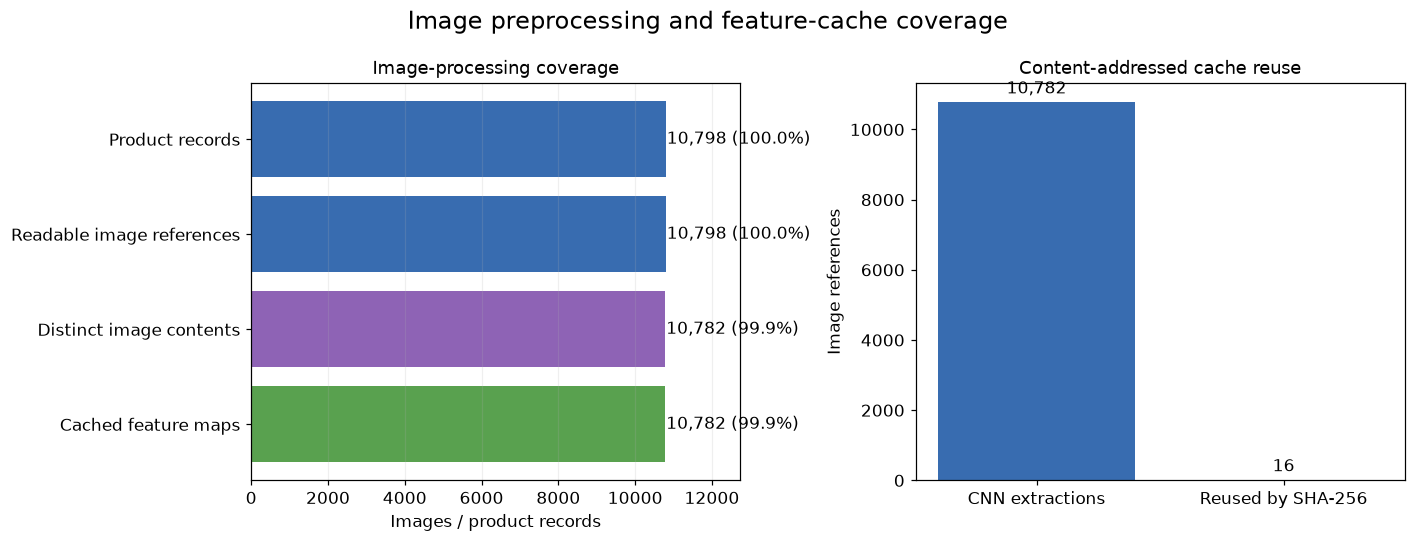

In [2]:
status = collections.Counter(r['image_status'] for r in rows)
cached_hashes = {p.stem for p in cache_files}
valid_hashes = set(unique)
overview = pd.DataFrame([
 {'stage':'Product records','count':len(rows)},
 {'stage':'Readable image references','count':len(ok)},
 {'stage':'Distinct image contents','count':len(unique)},
 {'stage':'Cached feature maps','count':len(cached_hashes & valid_hashes)}])
overview['percent_of_records'] = 100*overview['count']/len(rows)
overview.to_csv(FIG_DIR/'3_5_1_processing_coverage.csv',index=False,encoding='utf-8-sig')
display(overview.round(2))
fig, axes = plt.subplots(1,2,figsize=(13,5))
bars=axes[0].barh(overview.stage[::-1],overview['count'][::-1],color=[COLORS['green'],COLORS['purple'],COLORS['blue'],COLORS['blue']])
axes[0].set_xlabel('Images / product records'); axes[0].set_title('Image-processing coverage')
for b,v,p in zip(bars,overview['count'][::-1],overview.percent_of_records[::-1]): axes[0].text(v+25,b.get_y()+b.get_height()/2,f'{v:,} ({p:.1f}%)',va='center')
axes[0].set_xlim(0,len(rows)*1.18); axes[0].grid(axis='x',alpha=.2)
reuse=len(ok)-len(unique)
axes[1].bar(['CNN extractions','Reused by SHA-256'],[len(unique),reuse],color=[COLORS['blue'],COLORS['orange']])
axes[1].set_ylabel('Image references'); axes[1].set_title('Content-addressed cache reuse')
for c in axes[1].containers: axes[1].bar_label(c,fmt='{:,.0f}',padding=3)
fig.suptitle('Image preprocessing and feature-cache coverage')
fig.tight_layout(); savefig(fig,'figure_3_5_1_processing_coverage')

## 3.5.2 Original image dimensions and aspect ratios

,metric,mean,median,p05,p95
0,width,320.15,320.0,320.0,320.0
1,height,320.26,320.0,320.0,320.0
2,short_side,320.15,320.0,320.0,320.0
3,long_side,320.26,320.0,320.0,320.0
4,aspect_ratio,1.00,1.0,1.0,1.0


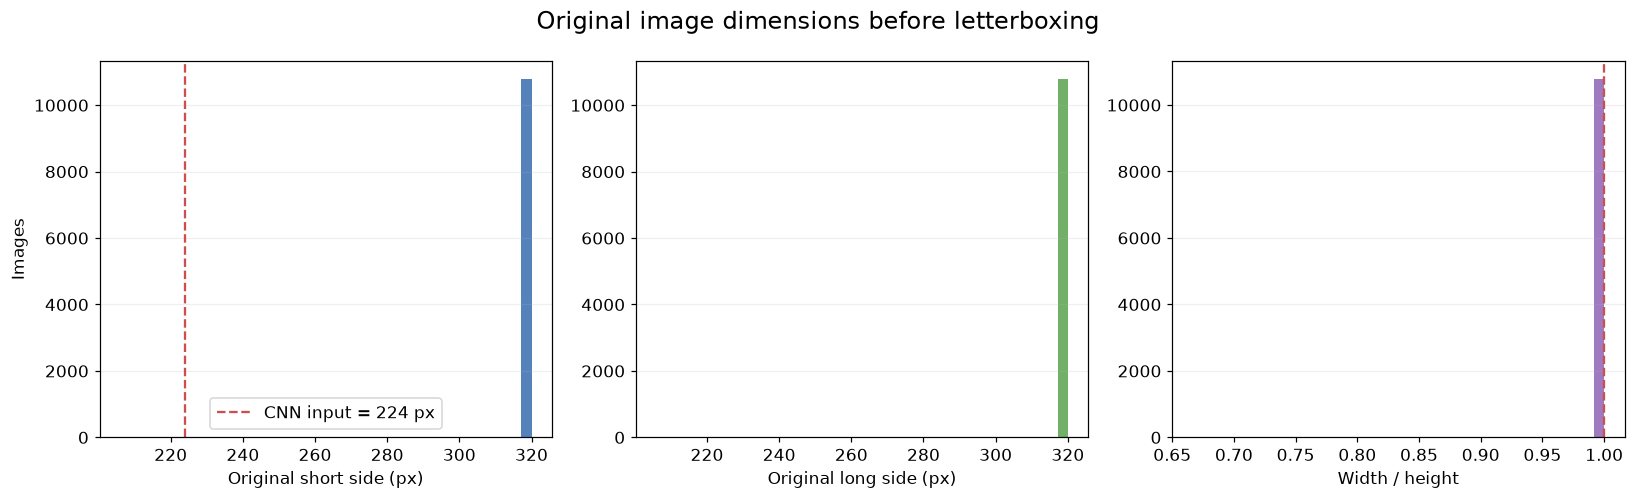

Short side below 224 px: 1 (0.01%)


In [3]:
sizes=np.asarray([r['image_size'] for r in ok],dtype=float)
width,height=sizes[:,0],sizes[:,1]; short=np.minimum(width,height); long=np.maximum(width,height); ratio=width/height
dimension_stats=pd.DataFrame({'metric':['width','height','short_side','long_side','aspect_ratio'],
 'mean':[width.mean(),height.mean(),short.mean(),long.mean(),ratio.mean()],
 'median':[np.median(width),np.median(height),np.median(short),np.median(long),np.median(ratio)],
 'p05':[np.percentile(width,5),np.percentile(height,5),np.percentile(short,5),np.percentile(long,5),np.percentile(ratio,5)],
 'p95':[np.percentile(width,95),np.percentile(height,95),np.percentile(short,95),np.percentile(long,95),np.percentile(ratio,95)]})
dimension_stats.to_csv(FIG_DIR/'3_5_2_image_dimension_summary.csv',index=False,encoding='utf-8-sig')
display(dimension_stats.round(2))
fig,axes=plt.subplots(1,3,figsize=(15,4.6))
axes[0].hist(np.clip(short,0,np.percentile(short,99)),bins=40,color=COLORS['blue'],alpha=.85)
axes[0].axvline(224,color=COLORS['red'],ls='--',label='CNN input = 224 px'); axes[0].set_xlabel('Original short side (px)'); axes[0].set_ylabel('Images'); axes[0].legend()
axes[1].hist(np.clip(long,0,np.percentile(long,99)),bins=40,color=COLORS['green'],alpha=.85); axes[1].set_xlabel('Original long side (px)')
axes[2].hist(np.clip(ratio,0,np.percentile(ratio,99)),bins=40,color=COLORS['purple'],alpha=.85)
axes[2].axvline(1,color=COLORS['red'],ls='--'); axes[2].set_xlabel('Width / height')
for ax in axes: ax.grid(axis='y',alpha=.2)
fig.suptitle('Original image dimensions before letterboxing')
fig.tight_layout(); savefig(fig,'figure_3_5_2_original_dimensions')
print(f'Short side below 224 px: {(short<224).sum():,} ({100*(short<224).mean():.2f}%)')

## 3.5.3 Examples before and after letterboxing

EXIF orientation is applied, images are converted to RGB, and aspect-ratio-preserving white padding creates a 224×224 input. The display below shows pixel-space letterboxing before tensor conversion and ImageNet normalization.

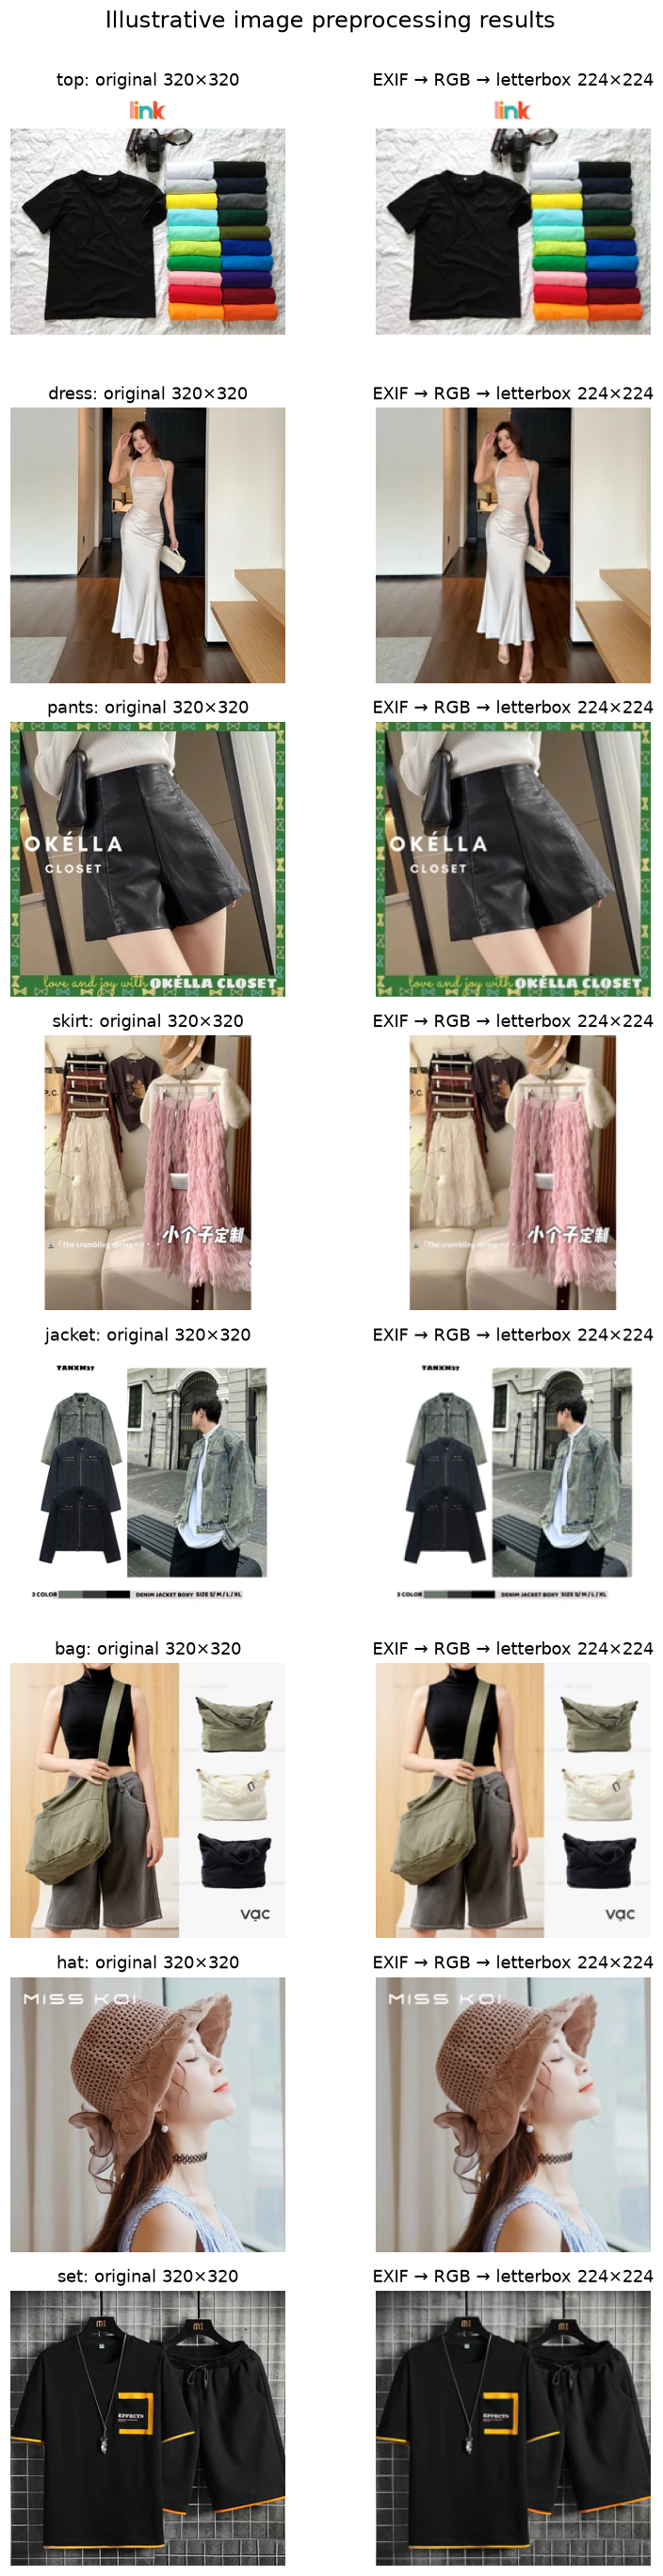

In [4]:
categories=['top','dress','pants','skirt','jacket','bag','hat','set']
samples=[]
for cat in categories:
    candidates=sorted([r for r in ok if r['category']==cat],key=lambda r:r['product_id'])
    if candidates: samples.append(candidates[len(candidates)//2])
fig,axes=plt.subplots(len(samples),2,figsize=(8,3.1*len(samples)))
for axrow,r in zip(axes,samples):
    with Image.open(r['image_path']) as im:
        corrected=ImageOps.exif_transpose(im).convert('RGB'); boxed=letterbox(im)
    axrow[0].imshow(corrected); axrow[0].axis('off'); axrow[0].set_title(f"{r['category']}: original {corrected.width}×{corrected.height}")
    axrow[1].imshow(boxed); axrow[1].axis('off'); axrow[1].set_title('EXIF → RGB → letterbox 224×224')
fig.suptitle('Illustrative image preprocessing results',y=1.002)
fig.tight_layout(); savefig(fig,'figure_3_5_3_letterbox_examples')

## 3.5.4 Cached ResNet18 feature maps

,cached_maps,shape,dtype,total_disk_mib,mean_file_kib,theoretical_values_per_map
0,10782,"(512, 7, 7)",float16,517.25,49.12,25088


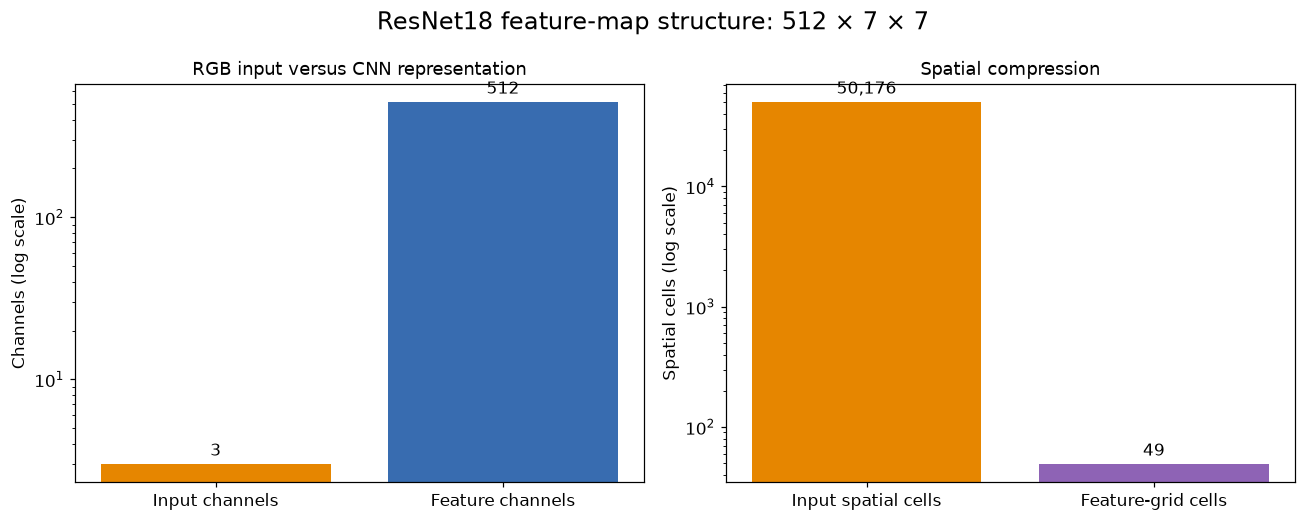

In [5]:
representative=np.load(cache_files[0],mmap_mode='r')
representative_shape=str(representative.shape); representative_dtype=str(representative.dtype)
byte_sizes=[p.stat().st_size for p in cache_files]
cache_stats=pd.DataFrame([{'cached_maps':len(cache_files),'shape':representative_shape,
 'dtype':representative_dtype,'total_disk_mib':sum(byte_sizes)/2**20,
 'mean_file_kib':np.mean(byte_sizes)/2**10,'theoretical_values_per_map':512*7*7}])
cache_stats.to_csv(FIG_DIR/'3_5_4_cache_summary.csv',index=False,encoding='utf-8-sig'); display(cache_stats.round(2))
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
axes[0].bar(['Input channels','Feature channels'],[3,512],color=[COLORS['orange'],COLORS['blue']])
axes[0].set_yscale('log'); axes[0].set_ylabel('Channels (log scale)'); axes[0].set_title('RGB input versus CNN representation')
for c in axes[0].containers: axes[0].bar_label(c,fmt='{:,.0f}',padding=3)
axes[1].bar(['Input spatial cells','Feature-grid cells'],[224*224,7*7],color=[COLORS['orange'],COLORS['purple']])
axes[1].set_yscale('log'); axes[1].set_ylabel('Spatial cells (log scale)'); axes[1].set_title('Spatial compression')
for c in axes[1].containers: axes[1].bar_label(c,fmt='{:,.0f}',padding=3)
fig.suptitle('ResNet18 feature-map structure: 512 × 7 × 7')
fig.tight_layout(); savefig(fig,'figure_3_5_4_feature_structure')

## 3.5.5 Feature-channel activation example

The channels below are selected by spatial variance for one deterministic example. CNN channels are latent filters and should not be assigned fashion-attribute names without additional validation.

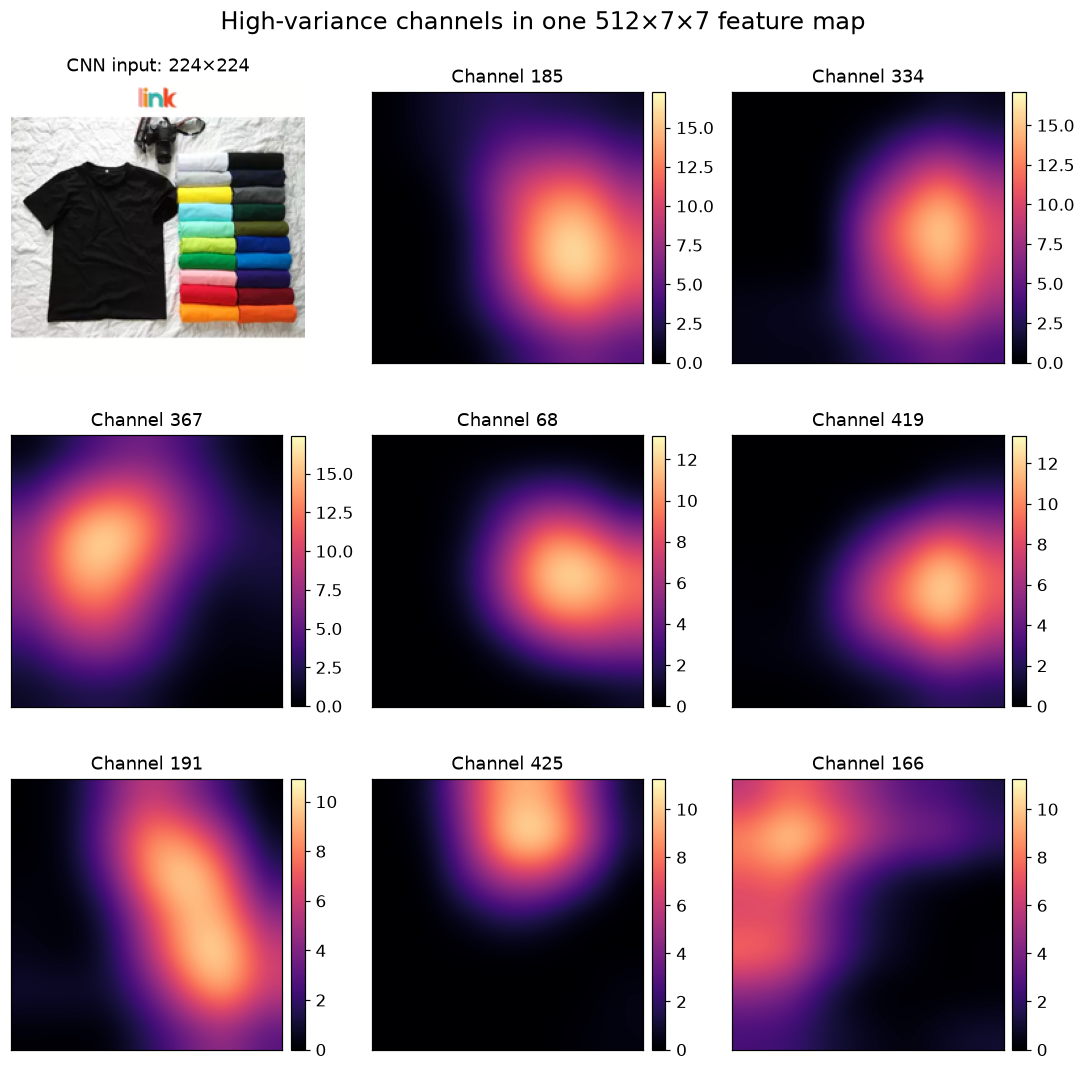

In [6]:
example=samples[0]; fmap=np.load(CACHE/f"{example['image_sha256']}.npy").astype(np.float32)
channel_ids=np.argsort(fmap.var(axis=(1,2)))[-8:][::-1]
with Image.open(example['image_path']) as im: boxed=letterbox(im)
fig,axes=plt.subplots(3,3,figsize=(10,10)); axes=axes.ravel()
axes[0].imshow(boxed); axes[0].axis('off'); axes[0].set_title('CNN input: 224×224')
for ax,c in zip(axes[1:],channel_ids):
    m=ax.imshow(fmap[c],cmap='magma',interpolation='bicubic'); ax.set_title(f'Channel {c}'); ax.set_xticks([]); ax.set_yticks([]); fig.colorbar(m,ax=ax,fraction=.046,pad=.03)
fig.suptitle('High-variance channels in one 512×7×7 feature map')
fig.tight_layout(); savefig(fig,'figure_3_5_5_feature_channels')

## 3.5.6 Spatial feature energy by product category

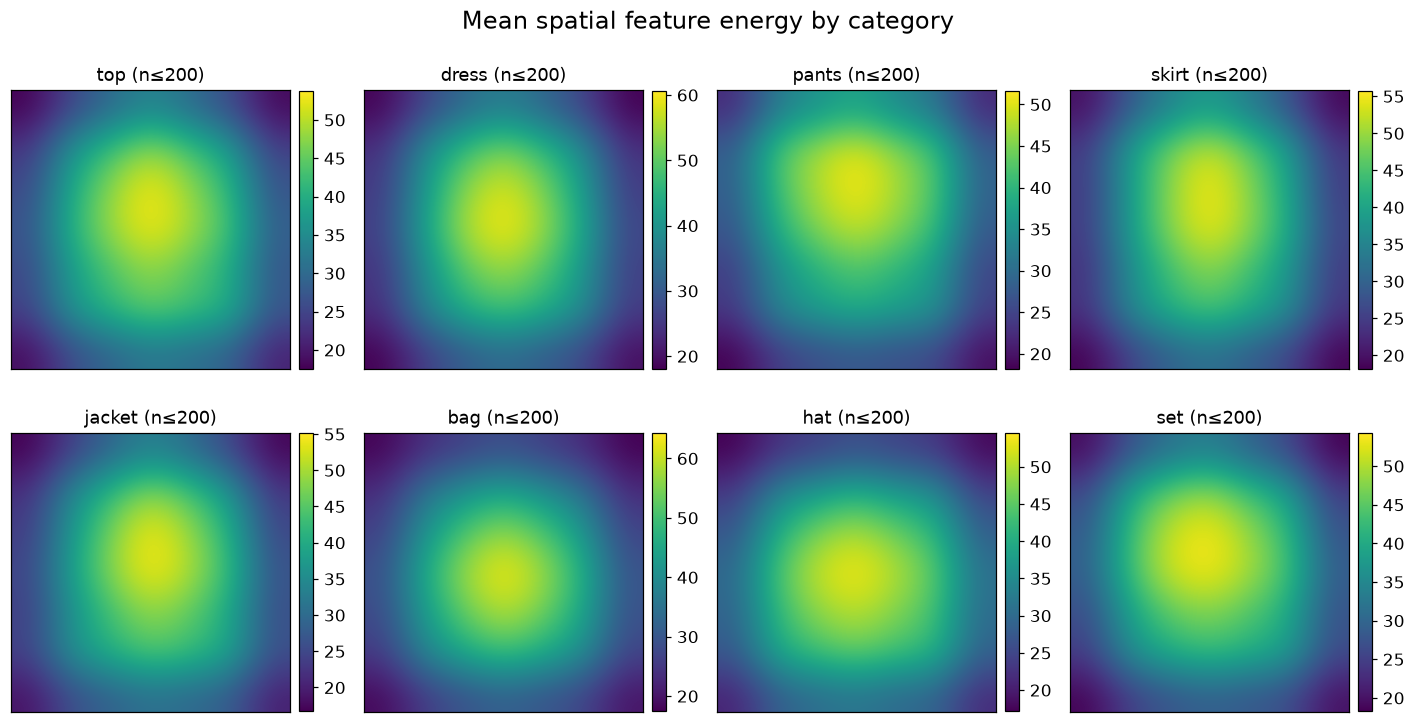

In [7]:
rng=np.random.default_rng(42); category_maps={}; sampled_rows=[]
for cat in categories:
    candidates=[r for r in unique.values() if r['category']==cat and (CACHE/f"{r['image_sha256']}.npy").exists()]
    pick=[candidates[i] for i in rng.choice(len(candidates),size=min(200,len(candidates)),replace=False)]
    sampled_rows.extend(pick)
    energy=np.stack([np.linalg.norm(np.load(CACHE/f"{r['image_sha256']}.npy").astype(np.float32),axis=0) for r in pick]).mean(0)
    category_maps[cat]=energy
fig,axes=plt.subplots(2,4,figsize=(13,7)); axes=axes.ravel()
for ax,(cat,energy) in zip(axes,category_maps.items()):
    im=ax.imshow(energy,cmap='viridis',interpolation='bicubic'); ax.set_title(f'{cat} (n≤200)'); ax.set_xticks([]); ax.set_yticks([]); fig.colorbar(im,ax=ax,fraction=.046,pad=.03)
for ax in axes[len(category_maps):]: ax.axis('off')
fig.suptitle('Mean spatial feature energy by category')
fig.tight_layout(); savefig(fig,'figure_3_5_6_spatial_energy_by_category')

## 3.5.7 Global-average-pooled feature space

Global average pooling converts each 512×7×7 feature map into a 512-dimensional vector. PCA below is descriptive and is not used to train the concept clusters. Categories originate from title-derived routing, so separation should not be interpreted as image-only classification accuracy.

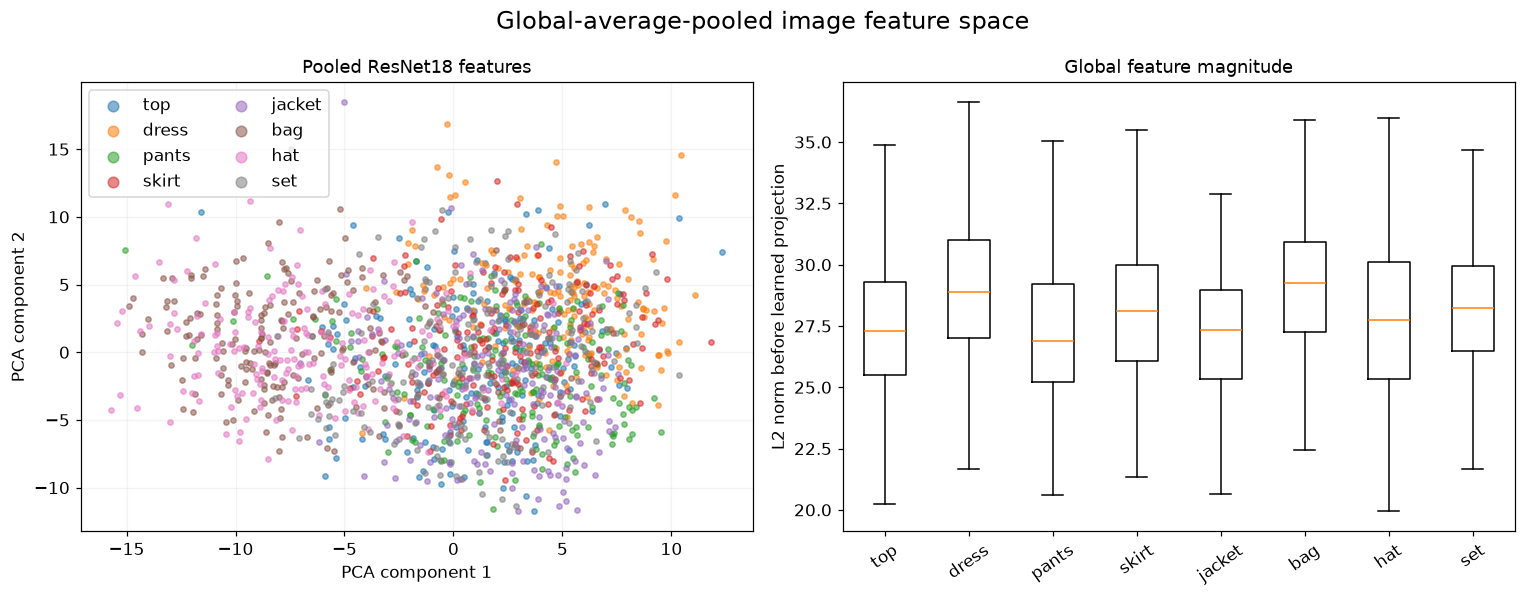

In [8]:
X=np.stack([np.load(CACHE/f"{r['image_sha256']}.npy").astype(np.float32).mean((1,2)) for r in sampled_rows])
labels=np.asarray([r['category'] for r in sampled_rows]); norms=np.linalg.norm(X,axis=1)
xy=PCA(n_components=2,random_state=42).fit_transform(StandardScaler().fit_transform(X))
fig,axes=plt.subplots(1,2,figsize=(14,5.5))
for cat in categories:
    m=labels==cat; axes[0].scatter(xy[m,0],xy[m,1],s=12,alpha=.55,label=cat)
axes[0].set_xlabel('PCA component 1'); axes[0].set_ylabel('PCA component 2'); axes[0].set_title('Pooled ResNet18 features'); axes[0].legend(markerscale=2,ncol=2); axes[0].grid(alpha=.15)
axes[1].boxplot([norms[labels==cat] for cat in categories],tick_labels=categories,showfliers=False)
axes[1].tick_params(axis='x',rotation=35); axes[1].set_ylabel('L2 norm before learned projection'); axes[1].set_title('Global feature magnitude')
fig.suptitle('Global-average-pooled image feature space')
fig.tight_layout(); savefig(fig,'figure_3_5_7_pooled_feature_space')

## Report-ready synthesis and exported files

In [9]:
print('REPORT-READY SYNTHESIS')
print(f"All {len(ok):,} readable product-image references were eligible for feature extraction. SHA-256 deduplication reduced these references to {len(unique):,} distinct image contents, each represented by one cached float16 feature map. The default frozen ImageNet-1K ResNet18 produced a 512×7×7 map ({512*7*7:,} values) from each EXIF-corrected, RGB-converted, 224×224 letterboxed and ImageNet-normalized input. The cache contains {len(cache_files):,} feature files occupying {sum(byte_sizes)/2**20:,.1f} MiB. Global average pooling subsequently yields a 512-dimensional vector per image, while the unpooled 7×7 maps retain coarse spatial information for attribute activation analysis.")
print('\nGenerated files:')
for p in sorted(FIG_DIR.iterdir()): print(' -',p.relative_to(ROOT))

REPORT-READY SYNTHESIS
All 10,798 readable product-image references were eligible for feature extraction. SHA-256 deduplication reduced these references to 10,782 distinct image contents, each represented by one cached float16 feature map. The default frozen ImageNet-1K ResNet18 produced a 512×7×7 map (25,088 values) from each EXIF-corrected, RGB-converted, 224×224 letterboxed and ImageNet-normalized input. The cache contains 10,782 feature files occupying 517.3 MiB. Global average pooling subsequently yields a 512-dimensional vector per image, while the unpooled 7×7 maps retain coarse spatial information for attribute activation analysis.

Generated files:
 - outputs\figures\image_features\3_5_1_processing_coverage.csv
 - outputs\figures\image_features\3_5_2_image_dimension_summary.csv
 - outputs\figures\image_features\3_5_4_cache_summary.csv
 - outputs\figures\image_features\figure_3_5_1_processing_coverage.png
 - outputs\figures\image_features\figure_3_5_1_processing_coverage.svg
 -